# Case Study 1 : Collecting Data from NewsAPI

Due Date: 11/10/2026, **BEFORE the beginning of class at 12:00pm EST**

## **NOTE: There are *always* last minute issues submitting the case studies.  DO NOT WAIT UNTIL THE LAST MINUTE!**

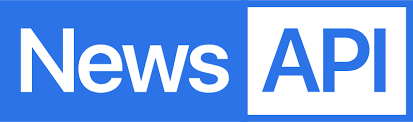

**TEAM Members:** Please EDIT this cell and add the names of all the team members in your team

    member 1 Murphy Doona
    
    member 2 Riley Ducharme
    
    
    ...

**Suggested Readings:**
* The NewsAPI documentation: https://newsapi.org/docs
* The Python library for NewsAPI: https://newsapi.org/docs/client-libraries/python
* The Python notebook I used in class 3
  * In fact, it is intentional that many of these questions can be answered directly from there (except for question 4)!
* The idea is to ease you into the case studies :-)

**Don't forget!**
* You will need to install the newsapi-python library to access NewsAPI
 * pip install newsapi-python
* You will need to get an API key from NewsAPI to access the data
  * https://newsapi.org/register


** NOTE **
* **Please don't forget to save the notebook frequently when working in IPython Notebook, otherwise the changes you made can be lost**.

# Problem 1 (20 points): Sampling NewsAPI data on a certain topic

* Select a topic that you are interested in, for example, "WPI" or "Lady Gaga"
* Use the NewsAPI to sample a collection of news articles about this topic. (It would be recommended that the number of articles should be larger than 200, but smaller than 100,000.)
* Store the articles you downloaded in a file on Google Drive (txt file or json file)

In [ ]:
! pip install newsapi-python

In [ ]:
from newsapi import NewsApiClient

# See https://newsapi.org/docs for more information
# on NewsAPI implementation.

API_KEY = 'f1d9d887e8e9484f8212a9bf82e02ec7'

newsapi = NewsApiClient(api_key=API_KEY)
print(newsapi)

In [ ]:

#From Gemini, asked for help to get the code to print more than 100 articles using the example code from the example Case Study
queries = ['NFL Chiefs', 'NFL Eagles', 'NFL Cowboys', 'NFL 49ers', 'NFL Bills', 'NFL trade', 'NFL injury']
all_articles = []

for q in queries:
    res = newsapi.get_everything(
        q=q,
        page_size=100,
        language='en'
    )
    all_articles.extend(res.get('articles', []))


unique = list({a['url']: a for a in all_articles if a.get('url')}.values())

everything = {'articles': unique, 'totalResults': len(unique)}

In [ ]:
print(everything)

{'articles': [{'source': {'id': 'bbc-news', 'name': 'BBC News'}, 'author': 'Ben Collins', 'title': 'Vikings are last unbeaten team as Chiefs lose - NFL week seven', 'description': "The Kansas City Chiefs and San Francisco 49ers lost in week seven of the NFL, leaving the Minnesota Vikings as this season's last unbeaten team.", 'url': 'https://www.bbc.co.uk/sport/american-football/articles/c61wvzxjxnjxo', 'urlToImage': 'https://ichef.bbci.co.uk/ace/branded_sport/1200/cpsprodpb/43d3/live/49565450-d0f7-11f1-a701-fddedf244c16.png', 'publishedAt': '2026-10-26T06:42:44Z', 'content': 'For the first time in the NFL, two divisions will go into week eight with all four teams having a record better than 50%.\r\nOne of those is the NFC North, topped by the Minnesota Vikings. Before the s… [+1069 chars]'}, {'source': {'id': 'bbc-news', 'name': 'BBC News'}, 'author': 'Ben Collins', 'title': 'Vikings, Chiefs and Cowboys beaten - NFL week eight', 'description': 'A wild weekend in the NFL saw Joe Burrow

### Report some statistics about the news articles you collected

* The topic of interest: NFL


* The total number of news articles collected:  456

In [ ]:
from google.colab import drive
import json

drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [ ]:
#"-p" is from Gemini, was having trouble with saving to the right folder
! mkdir  -p "gdrive/MyDrive/WPI/2026-2027/B Term/DS 3010/Case Study 1/NFL Data"

In [ ]:
! ls "gdrive/MyDrive/WPI/2026-2027/B Term/DS 3010/Case Study 1/NFL Data/foo.txt"

'gdrive/MyDrive/WPI/2026-2027/B Term/DS 3010/Case Study 1/NFL Data/foo.txt'


In [ ]:
data=json.dumps(everything, indent=1)

file=open('/content/gdrive/MyDrive/WPI/2026-2027/B Term/DS 3010/Case Study 1/NFL Data/foo.txt','w')
file.write(data)
file.close()

Exception ignored in: <_io.TextIOWrapper name='/content/gdrive/MyDrive/WPI/2026-2027/B Term/DS 3010/Case Study 1/NFL Data/foo.txt' mode='r' encoding='utf-8'>
Traceback (most recent call last):
  File "/tmp/ipykernel_5865/2883576486.py", line 3, in <cell line: 0>
OSError: [Errno 107] Transport endpoint is not connected


In [ ]:

#From Gemini, asked for help to get the code to print more than 100 articles
path = '/content/gdrive/MyDrive/WPI/2026-2027/B Term/DS 3010/Case Study 1/NFL Data/foo.txt'
with open(path, 'w') as f:
    json.dump(everything, f, indent=1)

In [ ]:
file=open('/content/gdrive/MyDrive/WPI/2026-2027/B Term/DS 3010/Case Study 1/NFL Data/foo.txt','r')
foo = file.read()
d = json.loads(foo)

print(len(d['articles']))
for article in d['articles'][:5]:
  print(f"author: {article['author']}")
  print(f"title: {article['title']}")
  print(f"description: {article['description']}")

541
author: Ben Collins
title: Vikings are last unbeaten team as Chiefs lose - NFL week seven
description: The Kansas City Chiefs and San Francisco 49ers lost in week seven of the NFL, leaving the Minnesota Vikings as this season's last unbeaten team.
author: Ben Collins
title: Vikings, Chiefs and Cowboys beaten - NFL week eight
description: A wild weekend in the NFL saw Joe Burrow and the Tampa Bay Buccaneers make history, while Lamar Jackson was sidelined on his return from injury.
author: BBC Sport
title: Chiefs coach defends decision to sign kicker Tucker
description: Kansas City Chiefs head coach Andy Reid defends the franchise's decision to sign Justin Tucker to its practice squad, stating the kicker has "done his suspension".
author: None
title: Allgeier stars in NFL plays of the week
description: Arizona Cardinals' Tyler Allgeier scores two incredible touchdowns as he stars in the best plays from this weekend's NFL action.
author: None
title: Nix's 62-yard touchdown & 'vintage 

*-----------------------

# Problem 2 (20 points): Analyzing News Articles with Frequency Analysis

**1. Word Count:**
* Use the news articles you collected in Problem 1, and compute the frequencies of the words being used in these articles.
* Note, you can use various parts of the articles (e.g. the title, the description, the content) to compute the word frequencies.
  * Which is most useful?
* Plot a table of the top 30 words with their counts

In [ ]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary
import time

authors = [ article['author'] for article in d['articles'] ]

sources = [ article['source']['name'] for article in d['articles'] ]

descriptions = [ article['description'] for article in d['articles'] ]

words = [ w
          for d in descriptions
              for w in d.split() ]


print(json.dumps(authors[0:5], indent=1))
print(json.dumps(sources[0:5], indent=1))
print(json.dumps(descriptions[0:5], indent=1))
print(json.dumps(words[0:5], indent=1))

from collections import Counter

for item in [authors, sources, words]:
    c = Counter(item)
    print(c.most_common()[:10])

from prettytable import PrettyTable

# From Gemini, asked it to use code from example Case Study to make word count and word table code
word_table = PrettyTable(field_names=['Word', 'Count'])
word_counts = Counter(words)

for item, count in word_counts.most_common(30):
    word_table.add_row([item, count])

word_table.align['Word'] = 'l'
word_table.align['Count'] = 'r'
print(word_table)

[
 "Ben Collins",
 "Ben Collins",
 "BBC Sport",
 null,
 null
]
[
 "BBC News",
 "BBC News",
 "BBC News",
 "BBC News",
 "BBC News"
]
[
 "The Kansas City Chiefs and San Francisco 49ers lost in week seven of the NFL, leaving the Minnesota Vikings as this season's last unbeaten team.",
 "A wild weekend in the NFL saw Joe Burrow and the Tampa Bay Buccaneers make history, while Lamar Jackson was sidelined on his return from injury.",
 "Kansas City Chiefs head coach Andy Reid defends the franchise's decision to sign Justin Tucker to its practice squad, stating the kicker has \"done his suspension\".",
 "Arizona Cardinals' Tyler Allgeier scores two incredible touchdowns as he stars in the best plays from this weekend's NFL action.",
 "\"Vintage\" Aaron Rodgers and Bo Nix's 62-yard touchdown feature in the best action from week seven of the NFL."
]
[
 "The",
 "Kansas",
 "City",
 "Chiefs",
 "and"
]
[(None, 186), ('Mike Florio', 26), ('Ron Kopp Jr.', 13), ('Michael David Smith', 13), ('Ben Zweiman

**2. Find the most popular news sources and authors in your articles**

* Please provide a table of the top 10 authors and sources that are the most popular among your collection.


In [ ]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary


#Partially from Gemini, combined with code from example Case Study
for label, data in (
                    ('Author', authors),
                    ('Source', sources)):
    pt = PrettyTable(field_names=[label, 'Count'])
    c = Counter(data)
    [ pt.add_row(kv) for kv in c.most_common()[:10] ]
    pt.align[label], pt.align['Count'] = 'l', 'r'
    print(pt)

+---------------------+-------+
| Author              | Count |
+---------------------+-------+
| None                |   186 |
| Mike Florio         |    26 |
| Ron Kopp Jr.        |    13 |
| Michael David Smith |    13 |
| Ben Zweiman         |    11 |
| Brandon Lee Gowton  |    10 |
| Josh Alper          |     8 |
| Matt Byham          |     7 |
| Charean Williams    |     7 |
| Jeremy Reisman      |     6 |
+---------------------+-------+
+---------------------------+-------+
| Source                    | Count |
+---------------------------+-------+
| Fox Sports                |   170 |
| NBCSports.com             |    59 |
| Yahoo Entertainment       |    54 |
| USA Today                 |    25 |
| BBC News                  |    21 |
| Buffalo Rumblings         |    16 |
| Nbcsportsphiladelphia.com |    16 |
| Arrowhead Pride           |    15 |
| New York Post             |    15 |
| Bleeding Green Nation     |    13 |
+---------------------------+-------+


**3. What is the lexical diversity in your descriptions and contents**

* For two popular authors or two popular sources, please compare the lexical diversity of their descriptions and contents.  
Which one is more diverse?  
  * Open ended questions: Does this make sense?  Why or why not? What might lexical diversity tell us about the author or source?

In [ ]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

def lexical_diversity(tokens):
    return 1.0*len(set(tokens))/len(tokens)


def average_words(statuses):
    total_words = sum([ len(s.split()) for s in statuses ])
    return 1.0*total_words/len(statuses)

print(lexical_diversity(words))
print(average_words(descriptions))


0.26600549882168106
18.824399260628464


Text(0.5, 0, 'Word Rank')

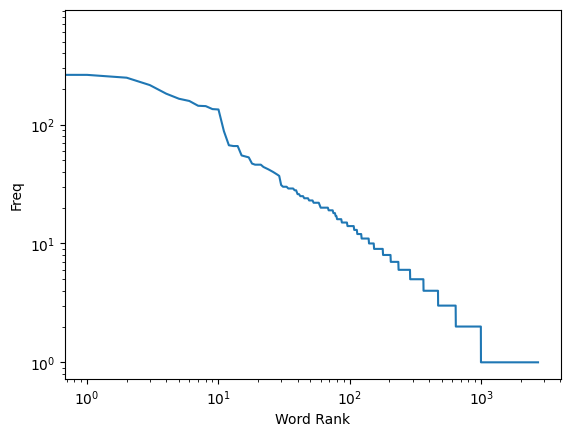

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline


word_counts = sorted(Counter(words).values(), reverse=True)



plt.loglog(word_counts)
plt.ylabel("Freq")
plt.xlabel("Word Rank")

* ------------------------

# Problem 3 (20 points): Image processing


* For each news article, download the image associated with it (using the urlToImage field).
* Do these images tell you anything about the news articles?  If so, what?

In [ ]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

#Partially from Gemini to reduce output size/quantity
from IPython.display import Image
from IPython.core.display import HTML

for i in range(5):
  print(everything['articles'][i]['title'])
  try:
    image = Image(url=everything['articles'][i]['urlToImage'])
    display(image)
  except ValueError:
    print('no image')

Vikings are last unbeaten team as Chiefs lose - NFL week seven


Vikings, Chiefs and Cowboys beaten - NFL week eight


Chiefs coach defends decision to sign kicker Tucker


Allgeier stars in NFL plays of the week


Nix's 62-yard touchdown & 'vintage Rodgers' - NFL best plays


These images give some insight into what the article could be about, especially if it includes a picture of a player or team. For example, if the cover image was just the two logos, it would be reasonable to guess that the article/story is about the matchup for a certain week. If the cover image contians one or two players, then it would be reasonable to guess that the article is about a player's performance or something regarding their off the field activity.

* Let's automate the process!  Use Hugging Face's transformers library to download a pre-trained image segmentation model.
  * See my notebook from class 3 for an example of how to do this.
* Open ended question: Collect statistics on what appears in the images for your news articles? What does this tell you?

In [ ]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary

! pip install -q datasets transformers evaluate timm albumentations

In [ ]:
from huggingface_hub import notebook_login

notebook_login()

Looking at the images, the most common objects observed by the Huggin Face model were "person" and "sports ball." This makes sense as most cover images for the articles collected are stills of players on the field. A large of the images are simply the logos of the teams playing either that week or in a specific game. The model was not able to find anything as logos are not always made of simply recognizable objects like "person" and are specific shapes that are not found anywhere else.

In [ ]:
#From Gemini, saves all of the images but just prints the first 5 to reduce the output size
from IPython.display import Image
image_urls = {}

for i in range(len(everything['articles'])):
  try:
    image_url = everything['articles'][i]['urlToImage']
    article = everything['articles'][i]
    image = Image(url=image_url)

    if len(image_urls) < 5:
      print(i)
      print(everything['articles'][i]['title'])
      display(image)

    image_urls[i] = image_url
  except ValueError:
    if len(image_urls) < 5:
      print('no image')

0
Vikings are last unbeaten team as Chiefs lose - NFL week seven


1
Vikings, Chiefs and Cowboys beaten - NFL week eight


2
Chiefs coach defends decision to sign kicker Tucker


3
Allgeier stars in NFL plays of the week


4
Nix's 62-yard touchdown & 'vintage Rodgers' - NFL best plays


In [ ]:
from transformers import pipeline
import requests
from PIL import Image, ImageDraw

obj_detector = pipeline("object-detection")

[transformers] No model was supplied, defaulted to facebook/detr-resnet-50 and revision 1d5f47b.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

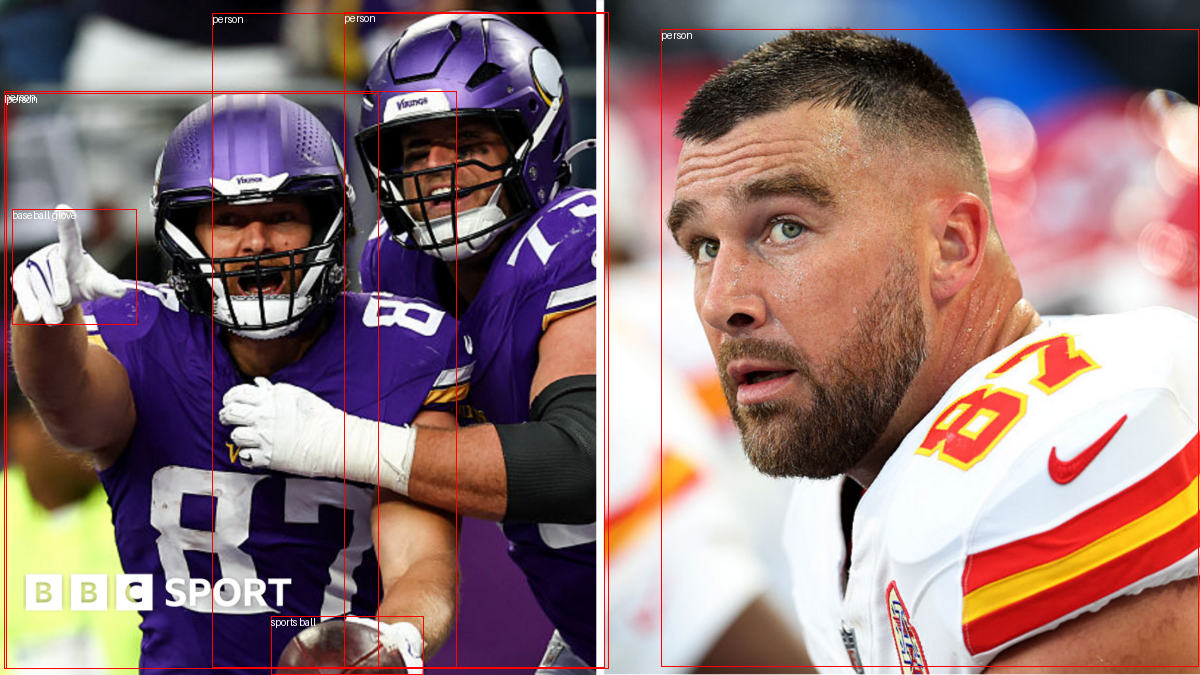

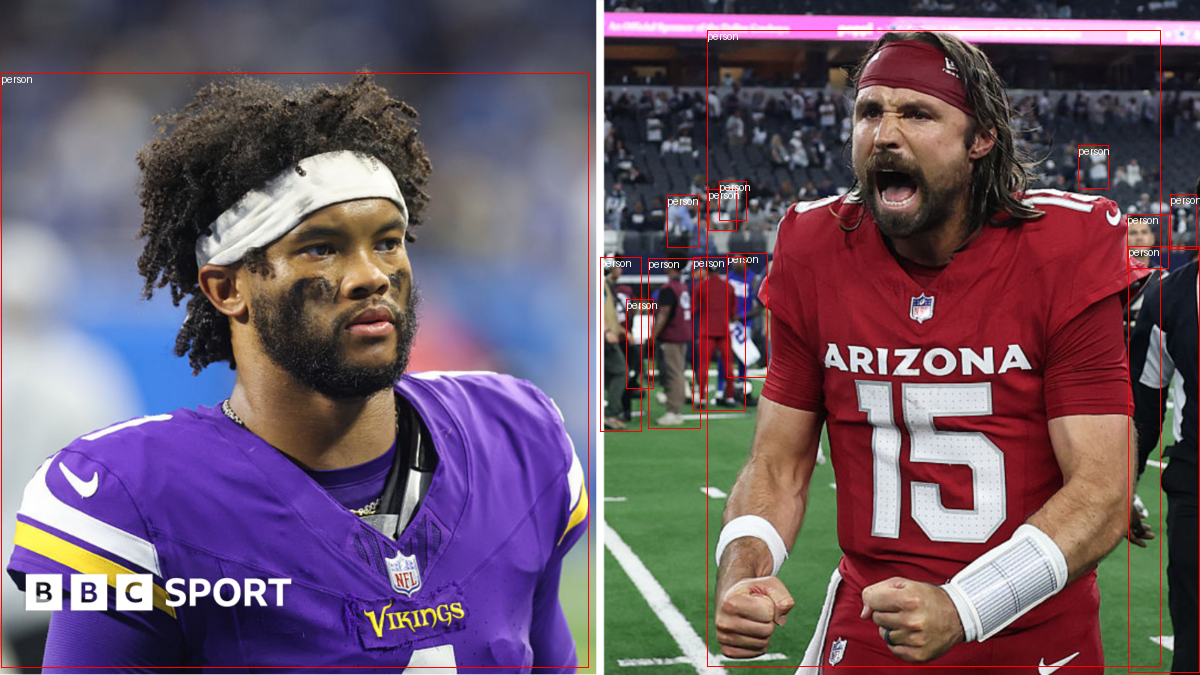

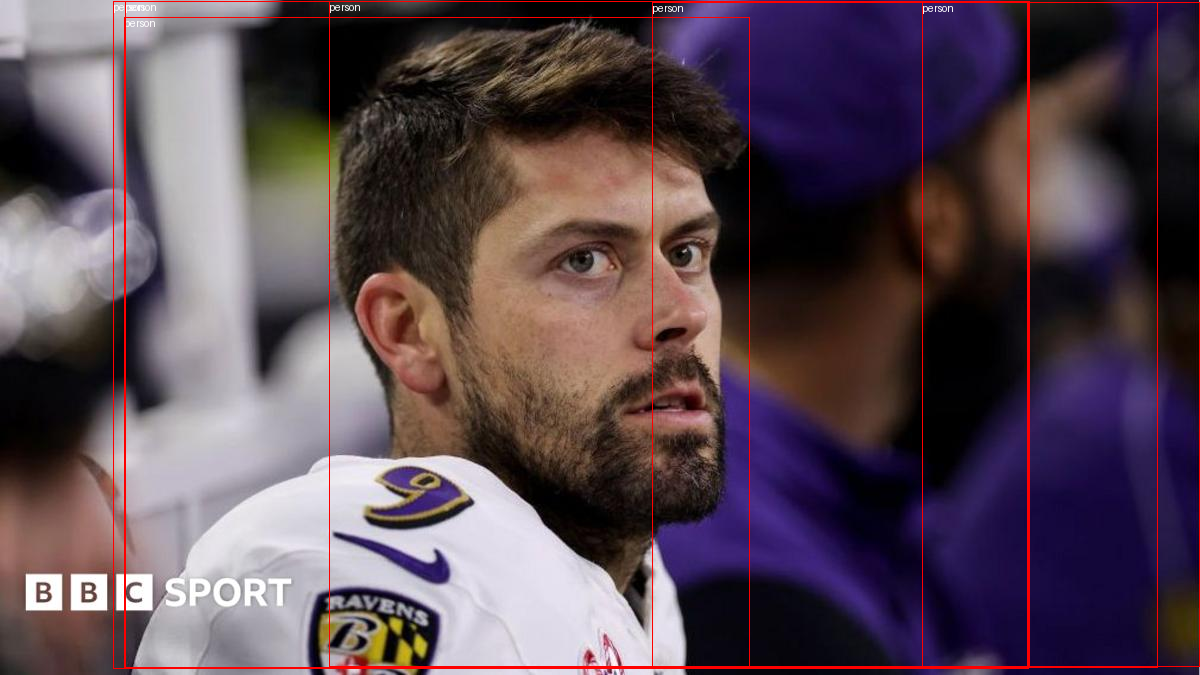

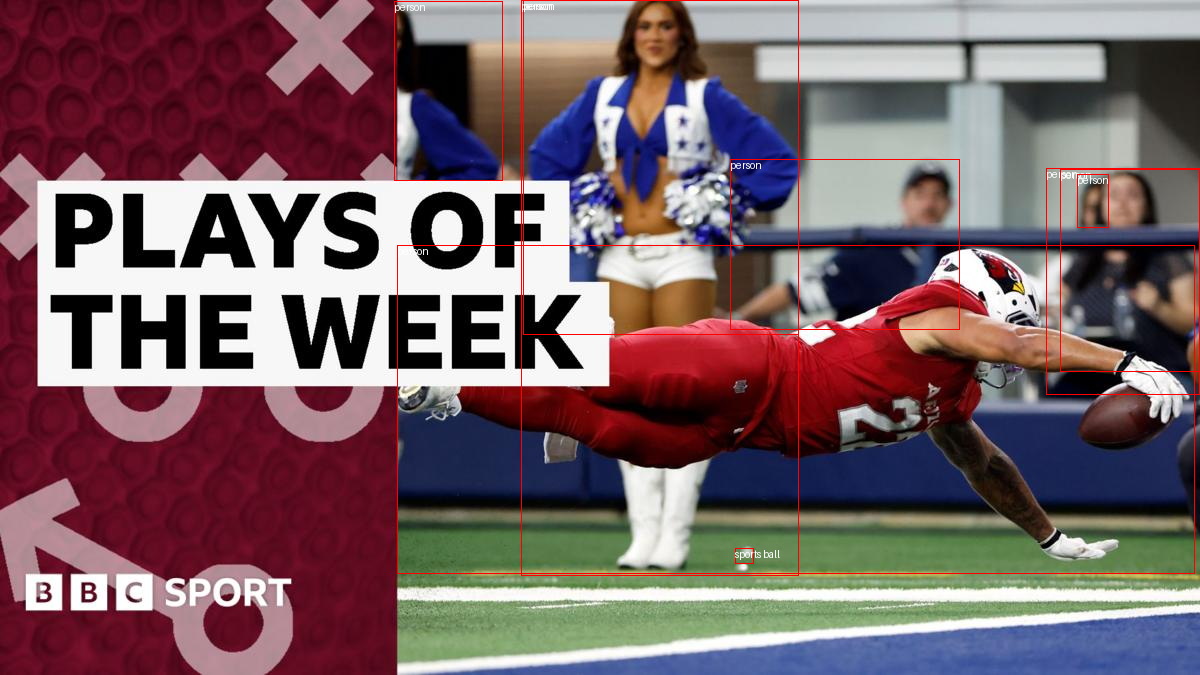

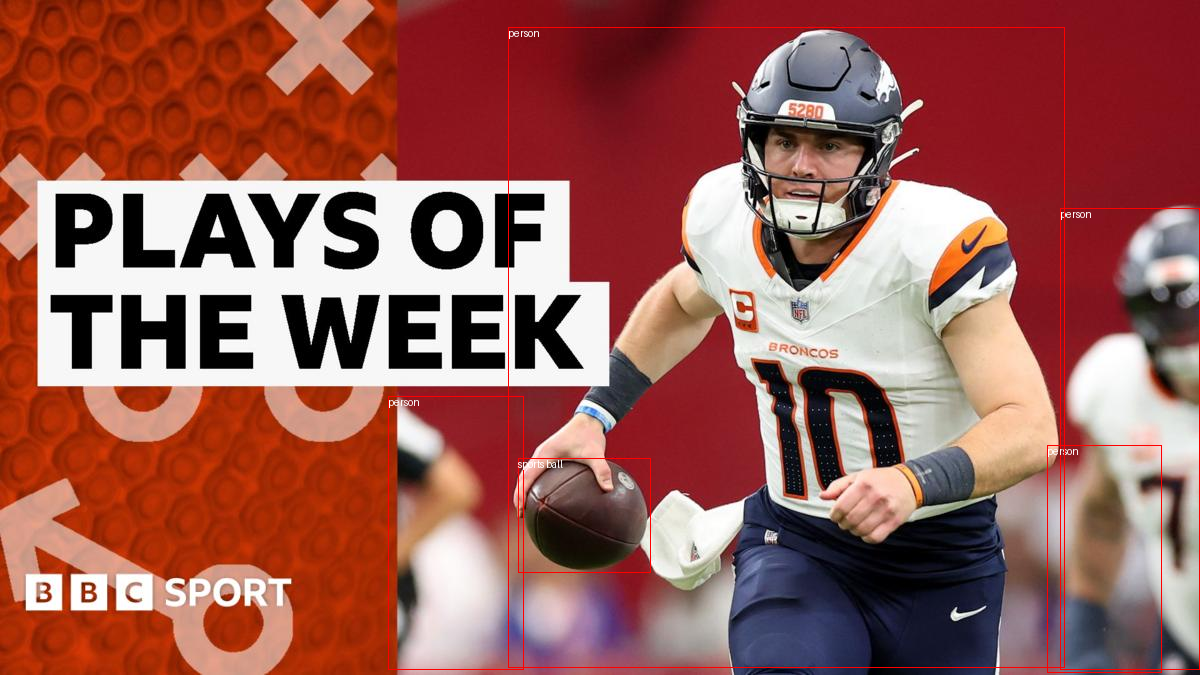

In [ ]:
#PIL line is from Gemini
import PIL
for key in list(image_urls.keys())[:5]:
  image_url = image_urls[key]
  image = PIL.Image.open(requests.get(image_url, stream=True).raw)

  results = obj_detector(image)

  draw = ImageDraw.Draw(image)

  for result in results:
    score, label, box = result["score"], result["label"], result["box"]
    x, y, x2, y2 = box['xmin'], box['ymin'], box['xmax'], box['ymax'],
    draw.rectangle((x, y, x2, y2), outline="red", width=1)
    draw.text((x, y), label, fill="white")

  display(image)

*------------------------

# Problem 4 (20 points): Business question

Run some additional experiments with your data to gain familiarity with the NewsAPI.

* Come up with a business question that NewsAPI data could help answer.
* Describe the business case.
* How could NewsAPI data help a company decide how to spend its resources.
* **[LLM only]** Ask your favorite LLM to provide three business ideas that this data could support and provide those ideas as part of your report.
* **[Human only]** Analyze those three ideas and come up with an idea for a product that you will form the organizing center for you work in the rest of the case studies.
* **[LLM only]**: Ask the LLM to act as a potential buyer and identify three reasons someone might not use your selected product.
* **[Human only]**: Decide which objection matters most. Propose a small experiment to test it, specify what you would measure, and define a result that would make you revise or cancel the idea.


In [ ]:
#----------------------------------------------
# Your code starts here
#   Please add comments or text cells in between to explain the general idea of each block of the code.
#   Please feel free to add more cells below this cell if necessary





1. Is it possible to predict an NFL (or any sports) players ranking in the top 100 based on popularity and highlights headlined in recent articles?
2. With the increase in sports betting and the prediction markets, sports news has became a big source for Polymarket, Kalshi, and the multitude of sports betting apps in our world currently. Where players rank and the popularity of views contributes a big part in the positive/negative influence sports commentators, writers, and voters hold
3. The number of articles related to a player's performance, either good or bad, could indicate the player's expected performance. Including articles mentioning certain players receiving awards and/or commendations can also demonstrate the level of greatness that both other players and sports writers believe this player to hold.

LLM Only


*   Promt: Given news data related to the NBA, give me three business ideas that this data could support
*   LLM Answer: ### 1. Real-Time Availability & Micro-Prediction Analytics Platform

With the rapid expansion of sports prediction markets (such as platforms like Polymarket and Kalshi) alongside high-frequency betting, millisecond-level information is critical. NFL news often breaks through fragmented channels—beat writer tweets, sudden pregame scratches, snap-count restrictions, and official injury reports.

* **The Concept:** An AI-powered news extraction and probability-modeling engine tailored for retail traders and fantasy managers.
* **How It Works:** Natural Language Processing (NLP) models monitor verified reporter feeds, team press releases, and locker-room audio in real time. It parses unstructured news (e.g., *"Player X is icing his knee and doubtful for the 4th quarter"*) into quantitative impact vectors, updating game spread probabilities, individual player prop projections, and live line movements before manual operators can react.
* **Monetization:** Tiered B2C subscriptions (API webhooks for algorithmic bettors, real-time push alerts for high-stakes fantasy players) and B2B data-feed licensing to regional sportsbooks and prediction market participants.

---

### 2. Player Brand Health & NIL Risk Intelligence Dashboard

NFL news covers far more than on-field box scores; off-field endorsements, trade rumors, legal disputes, and social media sentiment dominate the feed. As brands, apparel companies, and regional sponsors invest tens of millions into player partnerships, they lack automated tools to monitor real-time public sentiment and sponsor safety.

* **The Concept:** A B2B reputation intelligence tool designed for sports agencies, venture funds, and corporate sponsors.
* **How It Works:** The platform aggregates news articles, fan comment velocity, podcast transcripts, and local reporting to generate an ongoing "Brand Volatility & Sentiment Index" for every active player. If a player is involved in controversial news, trade friction, or viral off-field incidents, corporate sponsors receive early risk alerts, breach-of-contract monitoring, and automated valuation adjustments for upcoming campaign activations.
* **Monetization:** Annual enterprise SaaS contracts targeted at agency marketing arms (e.g., Athletes First, CAA, Excel Sports) and consumer brands managing NFL endorsement portfolios.

---

### 3. Hyper-Localized Automated Fan & Creator Content Studio

NFL news is heavily localized—a backup player’s snap count or an offensive coordinator’s tactical tweak is monumental news to beat reporters and local fanbases, but rarely covered by major national networks.

* **The Concept:** A headless, programmatic media platform that turns raw news data, game quotes, and injury updates into ready-to-publish short-form video scripts, data graphics, and localized newsletters.
* **How It Works:** The pipeline ingests daily team press notes, injury reports, and post-game transcripts. It automatically pairs news events with historical box-score context, generating chart graphics (e.g., *"How the offense operates when Player Y sits"*) and structured 60-second video briefs for team-specific content creators, YouTube channels, and regional sports blogs.
* **Monetization:** A monthly SaaS subscription for digital media outlets, independent creators, and team fan-communities to automate high-volume social content and data visualizations without requiring a full-time analytics desk.

After looking at the three business ideas generated from Gemini, we are going to incorporate parts of the first and second recommendations into our original concept. The first concept is in line with our main motivation of providing a service that consumers can use to gather qualitative data from news stories to provide more information to influence their choices about Fantasy Sports and prediction market platforms. The idea to also include sources outside of news articles is helpful and we will incorporate that into further Case Studies. The idea for our platform to use an AI-powered model to extract this data seems advanced, so we will begin forming the platform to follow the structure generated in concept 2. A dashboard of off the field information is a better inital focus compared to creating an AI model that predicts outcomes of games using on the field information, as this idea is nearly identical to existing prediction markets and consumer sports apps. Concept 3 would be a larger shift from our inital idea, and we believe the first two concepts to be more easily marketable to potential investment.

Prompt: Business Idea(specifically for the NFL): A free app/platform that gathers information(news articles, stats, social media posts, etc.) on player's or team's previous performances and recent updates to give the consumer information, thus influencing the consumer to positively or negatively "invest" into a player or team. This could be useful for Fantasy Sport managers or consumers using prediction markets to bet on player/team performance and end of season future awards. Act as a potential investor and identify three reasons someone might not use your selected product.

LLM Only:
Pivoting to a free, ad-supported or affiliate-driven consumer app actually heightens the skepticism from an institutional investor. Making the front-end free removes the friction of consumer subscription drop-off, but it introduces three much harder structural business problems:

---

### 1. Inverted Unit Economics (Server & API Costs Outpace Ad/Affiliate Yield)

Real-time news processing is computationally expensive. Running continuous NLP ingestion pipelines (web scraping, speech-to-text on locker-room audio, LLM sentiment extraction, push notifications) incurs fixed compute and third-party data API costs for every active user.

* **The Math:** A sports-content ad model typically yields a modest CPM of $4 to $12 on mobile displays. If an active user checks the app 3 times on a Sunday, generating 10 ad impressions, you might make 5 to 10 cents per user per month.
* **The Problem:** The combined cost of real-time infrastructure, cloud hosting, and push-alert bandwidth often consumes that entire margin. If your monetization relies instead on sportsbook/prediction affiliate conversions (CPA), most of your audience consists of established fantasy players who already have active accounts on DraftKings, FanDuel, Sleeper, or Kalshi. You cannot monetize existing account holders on new first-time deposit (FTD) bounties.

---

### 2. The Distribution Treadmill Against Entrenched Free Giants

In the consumer mobile landscape, "free" is not a differentiator—it is the baseline expectation.

* **The Incumbent Advantage:** Fantasy managers already get instant, free push alerts directly from **Sleeper**, **Twitter/X**, and fantasy platforms that possess massive war chests and millions of active users.
* **The Acquisition Trap:** App Store optimization (ASO) and organic word-of-mouth are rarely sufficient in saturated sports categories. Without paid user acquisition (Meta/Google/TikTok ads), user growth stalls. But because your app is free, your Average Revenue Per User (ARPU) is negligible. You end up spending $3 to $6 to acquire a user who generates $0.40 in ad revenue during the football season before vanishing in February.

---

### 3. Misaligned Incentives & Reputational Degradation

Free consumer sports apps that fail to monetize via subscriptions almost always resort to predatory affiliate placements or cluttering the UI with programmatic ads.

* **The Brand Conflict:** The moment an app's primary revenue shifts to affiliate links from sportsbooks and prediction exchanges, the product's objective integrity is compromised in the eyes of the consumer. Users immediately suspect that the "bullish/bearish" sentiment analysis is skewed to push bets with high bookmaker margins (e.g., long-shot parlays or volatile player awards) rather than genuine analytical edges.
* **The Churn Cycle:** Once users perceive the app as an affiliate marketing funnel disguised as an analysis tool, retention drops off precipitously.

---

### Hard Questions for the Pitch

1. **Monetization Mechanics:** If the app is free, what specific monetization model generates your revenue: programmatic ads, affiliate rev-share, or licensing the aggregated sentiment data B2B?
2. **First-Time Depositor (FTD) Reality:** If relying on sportsbook affiliate revenue, what percentage of your target demographic doesn't already have accounts on the major platforms?
3. **Offseason Cost Strategy:** What is the burn rate to maintain data pipelines, app updates, and server infrastructure between February and August when daily active users (DAU) fall by 80%?

The objection that matters most to us is gaining and retaining consumer attention. Many apps/platforms that provide fantasy sports and prediction markets already include some kind of article/description with live updates regarding games and players. It will be difficult for us to convice consumers that use these platforms to incorporate ours into their routine. Along with joining the platform, it has to offer something that other platforms do not or present information in a desirebale way. An experiment to test the willingness of consumers to join our platform would be a survey. This survey would ask about willingness add another app/platform to their typical app rotation. Another test would be having a sample of users all sign up for the app. Over a two week span, we can track how often they opened the app, for how long they used the app, and if they used it at all compared to competitors. A result that would make us revise the idea would be the survey results where participants can give feedback on what they do not like about current sports information platforms so we fill those gaps. A result that would make use cancel the idea would be low retention rate of using the application from the sample of users.

*-----------------
# Done

All set!

** What do you need to submit?**

* **Notebook File**: Save this IPython notebook, and find the notebook file in your folder (for example, "filename.ipynb"). This is the file you need to submit. Please make sure all the plotted tables and figures are in the notebook. If you used "ipython notebook --pylab=inline" to open the notebook, all the figures and tables should have shown up in the notebook.
**Also, you must cite any LLM assistance and any other support you get for the project.**




* **Report**: please prepare a report (less than 10 pages) to report what you found in the data.
    * What data you collected?
    * Why this topic is interesting or important to you? (Motivations)
    * How did you analyse the data?
    * What did you find in the data?


     (please include figures or tables in the report, but no source code)

* **Video**: A 2–3-minute video pitch to a Venture Capitalist. This should discuss the data you gathered, the topic of interest, the methodology you used to gather the data, and provide a preview of your product. **Submit only a link to your video, not the video file. Include the link to your video in your report file. You may upload your video to Google Drive, OneDrive, YouTube (Unlisted) or any other video-sharing platform. Ensure that anyone with the shared link can view the video without requesting access.**

Please compress the notebook file and the report (including the video link) into a zipped file and submit it on canvas.wpi.edu for grading.



# Grading Criteria:

** Total Points: 100 **


---------------------------------------------------------------------------
** Notebook results:  **
    Points: 80


    -----------------------------------
    Question 1:
    Points: 20
    -----------------------------------
    
    (1) Select a topic that you are interested in.
    Points: 6
    
    (2) Use the NewsAPI to sample a collection of news articles about this topic. (It would be recommended that the number of articles should be larger than 200, but smaller than 100,000. Please check whether the total number of articles collected is larger than 200.)
    Points: 10
    
    
    (3) Store the articles you downloaded into a file on Google Drive (txt file or json file)
    Points: 4
    
    
    -----------------------------------
    Question 2:
    Points: 20
    -----------------------------------
    
    1. Word Count

    (1) Use the news articles you collected in Problem 1, and compute the frequencies of the words being used in these articles.
    Points: 5

    (2) Plot a table of the top 30 words with their counts
    Points: 5
    
    2. Please provide a table of the top 10 authors and sources that are the most popular among your collection.
    Points: 5
    
    3. For two popular authors or two popular sources, please compare the lexical diversity of their descriptions and contents.
    Points: 5
      
    -----------------------------------
    Question 3:
    Points: 20
    -----------------------------------
    
    (1) For each news article, download the image associated with it (using the urlToImage field).
    Points: 10

    (2) Use Hugging Face's transformers library to download a pre-trained image segmentation model.
    Points: 10
  
    -----------------------------------
    Question 4:  Business question
    Points: 20
    -----------------------------------
        Novelty: 10
        Interestingness: 10
    -----------------------------------
    Run some additional experiments with your data to gain familiarity with the NewsAPI.  Come up with a business question and describe how NewsAPI data can help you answer that question.

    -----------------------------------
    Report and video:  
    Points: 20
    -----------------------------------
    


